# Entanglement entropy analysis
Tracks the Von Neumann entanglement entropy of `MerlinTunableSimple`'s quantum layer
(default bipartition: encoded modes vs. the extra mode) over training, alongside model
accuracy (relative L2 error), averaged over seeds.

Settings: same baseline PDE/sampler config as `Reproducibility.ipynb` (freq=0.5, default
sampler, 600 epochs), same seeds as `ModelSize_scaling.ipynb`.

## 0 - Setup

In [1]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinTunableSimple
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_entropy_accuracy_trajectory, plot_solution_comparison

# Prefer CUDA, then Apple Silicon GPU (MPS), then fall back to CPU.
if torch.cuda.is_available():
    device = torch.device('cuda')
# elif torch.backends.mps.is_available():
#     device = torch.device('mps')
else:
    device = torch.device('cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Config

In [6]:
SEEDS = [42, 666, 69, 67, 13]
EPOCHS = 300

pde = HeatEquation(freq=2.5)

n_encoding_layers = 1

## 2 - Train for each seed, recording entropy + rel L2 every epoch

`eval_callback` runs `evaluate()` on the full (x, t) grid after every epoch, capturing
both the model's Von Neumann entropy (from its default bipartition) and its relative
L2 error against the exact solution.

In [4]:
entropy_trajectories = []
rel_l2_trajectories = []

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)

    entropy_traj = []
    rel_l2_traj = []

    def eval_callback(m, epoch):
        metrics, *_ = evaluate(m, pde, device=device, dtype=dtype, verbose=False)
        entropy_traj.append(metrics["entropy"])
        rel_l2_traj.append(metrics["rel_l2"])

    train(
        model=model, pde=pde, loss_fn=total_loss,
        epochs=EPOCHS, log_every=EPOCHS, seed=seed,
        device=device, dtype=dtype,
        eval_every=1, eval_callback=eval_callback,
    )

    entropy_trajectories.append(entropy_traj)
    rel_l2_trajectories.append(rel_l2_traj)

entropy_trajectories = np.array(entropy_trajectories)  # (n_seeds, epochs)
rel_l2_trajectories  = np.array(rel_l2_trajectories)   # (n_seeds, epochs)


Seed 42
Parameters — total: 398  trainable: 398

Training for 5 epochs on mps  (dtype=torch.float32)
Epoch     1/5 | Loss: 1.5641e+00 | PDE: 8.12e-07 | Cons: 3.11e-02 | IC: 1.04e-01 | BC: 5.22e-01 | Time: 4.4s
Epoch     5/5 | Loss: 1.7516e+00 | PDE: 2.67e-05 | Cons: 5.50e-03 | IC: 1.24e-01 | BC: 5.13e-01 | Time: 19.5s

Done — 19.5s total


## 3 - Aggregate across seeds and plot

Saved: figures/entanglement_entropy/entropy_accuracy_trajectory.png


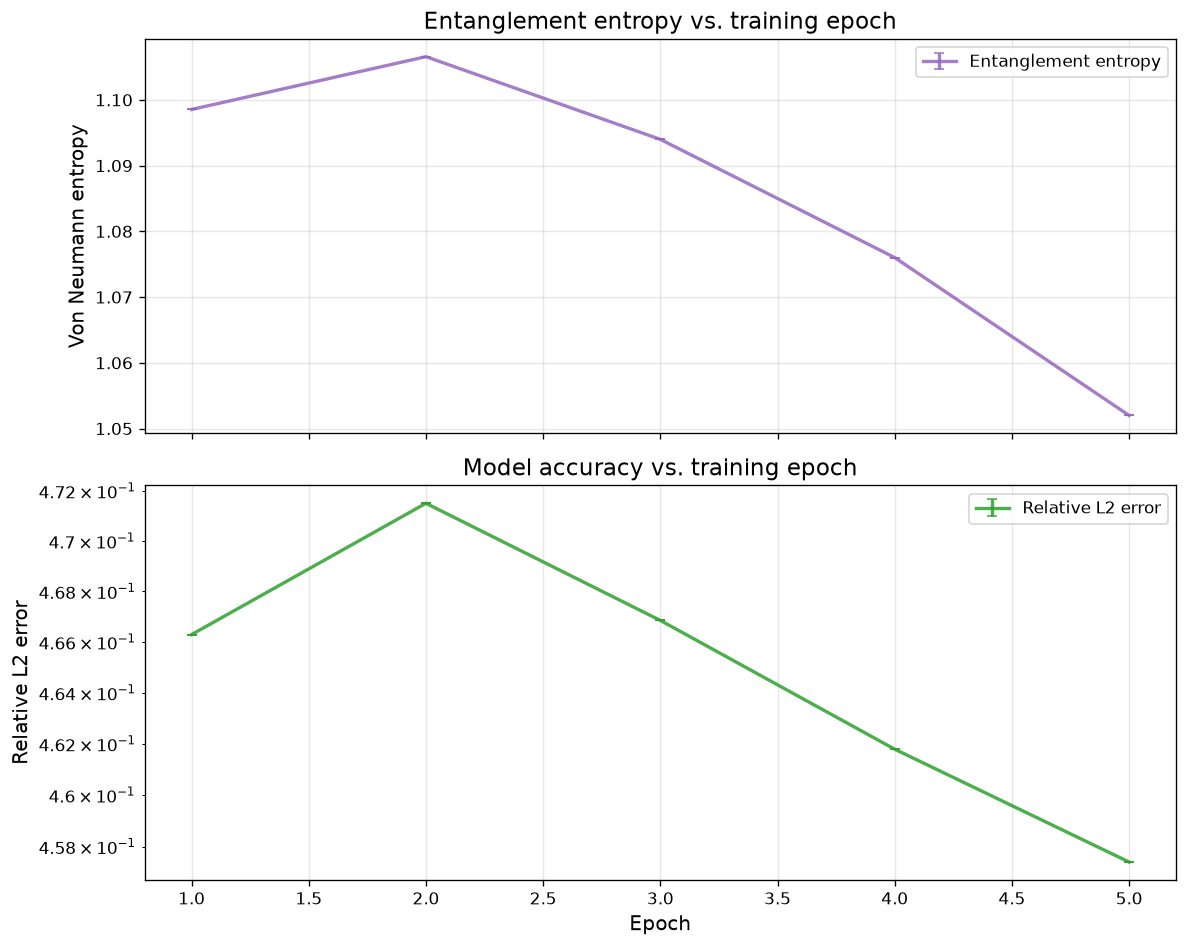

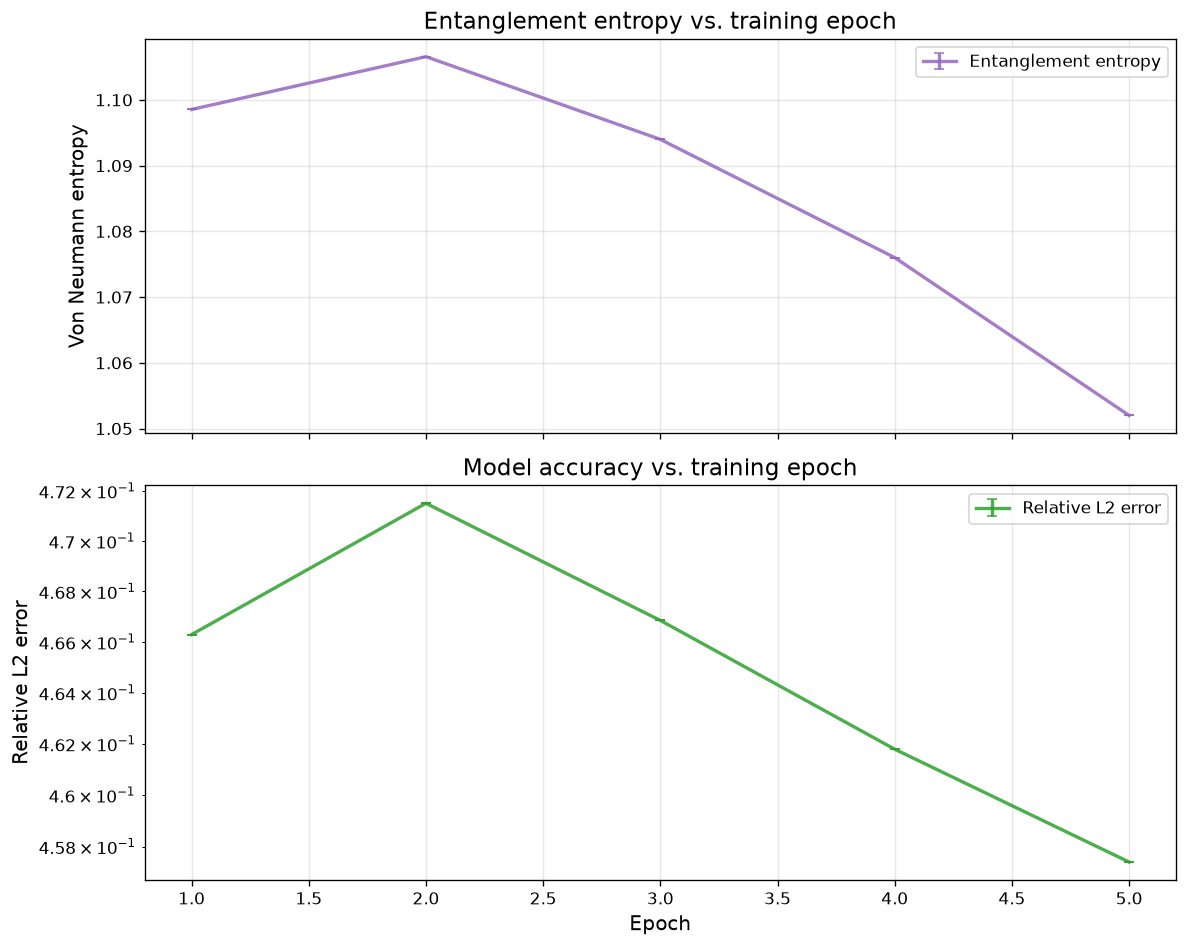

In [5]:
epochs_axis = np.arange(1, EPOCHS + 1)

entropy_mean = entropy_trajectories.mean(axis=0)
entropy_std  = entropy_trajectories.std(axis=0)
rel_l2_mean  = rel_l2_trajectories.mean(axis=0)
rel_l2_std   = rel_l2_trajectories.std(axis=0)

plot_entropy_accuracy_trajectory(
    epochs_axis, entropy_mean, entropy_std, rel_l2_mean, rel_l2_std,
    save_path="figures/entanglement_entropy/entropy_accuracy_trajectory.png",
    show=True,
)

## 4 - Data re-uploading (doubled angle encoding) vs. parameter-matched classical baseline

`MerlinTunableSimple(n_encoding_layers=2)` re-uploads the encoded features through a
second angle-encoding pass over the *same* `feature_size` modes (data re-uploading),
interleaved with an extra trainable entangling layer, instead of growing `feature_size`
itself. This doubles the number of angle-encoding gates while keeping `n_modes` — and
therefore the Fock-basis Hilbert space / simulation cost — identical to the 1-layer
baseline (growing `feature_size` instead would grow the Hilbert space combinatorially:
35 -> 1287 dimensions for feature_size 4 -> 8, a ~37x blowup).

`match_classical_param_count` builds a classical MLP (`ClassicalTunableSimple`) with the
exact same total trainable parameter count as the 2-layer quantum model, so accuracy
differences below reflect architecture, not capacity budget.

**Runtime note:** the section 2 baseline run above (1 seed, 600 epochs) took ~44 minutes
on this M3's MPS backend. This section trains 3 models, so a full run at the same
settings is ~2+ hours. Consider lowering `COMPARISON_EPOCHS` / `COMPARISON_SEEDS` below
for a first pass.

In [ ]:
# from src.models import ClassicalTunableSimple, match_classical_param_count

# COMPARISON_SEEDS = SEEDS
# COMPARISON_EPOCHS = EPOCHS

# _reference_quantum = MerlinTunableSimple(feature_size=4, n_encoding_layers=2)

# MODEL_BUILDERS = {
#     "quantum (1 encoding layer)": lambda: MerlinTunableSimple(feature_size=4, n_encoding_layers=1),
#     "quantum (2 encoding layers)": lambda: MerlinTunableSimple(feature_size=4, n_encoding_layers=2),
#     "classical (param-matched)": lambda: match_classical_param_count(
#         _reference_quantum, feature_size=4, n_encoding_layers=2
#     ),
# }

# for name, build in MODEL_BUILDERS.items():
#     n_params = sum(p.numel() for p in build().parameters())
#     print(f"{name:28s} total params: {n_params}")

### 4.1 - Train each model across seeds

Same per-epoch entropy + rel L2 tracking as section 2. The classical model's `forward`
returns `(u, ux_hat)` with no entropy term — `evaluate()` already handles that (entropy
is `None` when the model doesn't return one), so `entropy_traj` stays a list of `None`s
for the classical run and is skipped when plotting.

In [ ]:
# comparison_rel_l2 = {}   # name -> (n_seeds, epochs)
# comparison_entropy = {}  # name -> (n_seeds, epochs), quantum models only

# for name, build in MODEL_BUILDERS.items():
#     rel_l2_runs = []
#     entropy_runs = []

#     for seed in COMPARISON_SEEDS:
#         print(f"\n{'='*60}\n{name} — seed {seed}\n{'='*60}")
#         model = build().to(device)

#         rel_l2_traj = []
#         entropy_traj = []

#         def eval_callback(m, epoch):
#             metrics, *_ = evaluate(m, pde, device=device, dtype=dtype, verbose=False)
#             rel_l2_traj.append(metrics["rel_l2"])
#             entropy_traj.append(metrics["entropy"])

#         train(
#             model=model, pde=pde, loss_fn=total_loss,
#             epochs=COMPARISON_EPOCHS, log_every=COMPARISON_EPOCHS, seed=seed,
#             device=device, dtype=dtype,
#             eval_every=1, eval_callback=eval_callback,
#         )

#         rel_l2_runs.append(rel_l2_traj)
#         entropy_runs.append(entropy_traj)

#     comparison_rel_l2[name] = np.array(rel_l2_runs)
#     if entropy_runs[0][0] is not None:
#         comparison_entropy[name] = np.array(entropy_runs)

### 4.2 - Aggregate across seeds and plot

In [ ]:
# from src.plotter import plot_model_comparison_trajectory

# comparison_epochs_axis = np.arange(1, COMPARISON_EPOCHS + 1)

# rel_l2_by_model = {
#     name: (arr.mean(axis=0), arr.std(axis=0))
#     for name, arr in comparison_rel_l2.items()
# }
# entropy_by_model = {
#     name: (arr.mean(axis=0), arr.std(axis=0))
#     for name, arr in comparison_entropy.items()
# }

# plot_model_comparison_trajectory(
#     comparison_epochs_axis,
#     rel_l2_by_model,
#     entropy_by_model=entropy_by_model,
#     save_path="figures/entanglement_entropy/encoding_layers_vs_classical.png",
#     show=True,
# )

## 5 - Entanglement entropy as a function of (x, t)

Sections 2-4 tracked entropy as a single scalar per epoch (mean over the evaluation
grid). `MerlinTunableSimple.forward()` now returns the *per-sample* entropy tensor
instead of pre-reducing it with `.mean()`, so `evaluate()` can reshape it against the
(x, t) grid it was computed on — exposed as `metrics["entropy_grid"]`, shape `(nx, nt)`.
`entropy_grid` is `None` for models that only return a scalar (e.g. the classical
baseline, or any model that still calls `.mean()` inside its own `forward()`).

Trains one fresh model per seed in `SEEDS` (same seeds as section 2), evaluates each at
the end of training, and plots the entropy field averaged across seeds.


Seed 42
Parameters — total: 310  trainable: 310

Training for 300 epochs on mps  (dtype=torch.float32)
Epoch     1/300 | Loss: 4.8509e+00 | PDE: 6.39e-06 | Cons: 1.65e-02 | IC: 4.84e-01 | BC: 4.90e-03 | Time: 3.2s
Epoch    25/300 | Loss: 4.0213e+00 | PDE: 6.08e-05 | Cons: 1.31e-03 | IC: 4.01e-01 | BC: 8.12e-03 | Time: 60.4s
Epoch    50/300 | Loss: 4.1083e+00 | PDE: 2.00e-04 | Cons: 1.02e-03 | IC: 4.10e-01 | BC: 7.45e-03 | Time: 120.0s
Epoch    75/300 | Loss: 4.9229e+00 | PDE: 1.17e-03 | Cons: 7.68e-03 | IC: 4.92e-01 | BC: 3.32e-03 | Time: 179.6s
Epoch   100/300 | Loss: 4.3114e+00 | PDE: 2.00e-02 | Cons: 1.17e-01 | IC: 4.23e-01 | BC: 5.17e-02 | Time: 241.7s
Epoch   125/300 | Loss: 4.8378e+00 | PDE: 2.53e-02 | Cons: 1.08e-01 | IC: 4.78e-01 | BC: 2.37e-02 | Time: 305.1s
Epoch   150/300 | Loss: 4.0821e+00 | PDE: 9.18e-02 | Cons: 4.47e-01 | IC: 3.87e-01 | BC: 7.11e-02 | Time: 367.5s
Epoch   175/300 | Loss: 2.9740e+00 | PDE: 1.65e-01 | Cons: 2.72e+00 | IC: 2.44e-01 | BC: 9.35e-02 | Time: 42

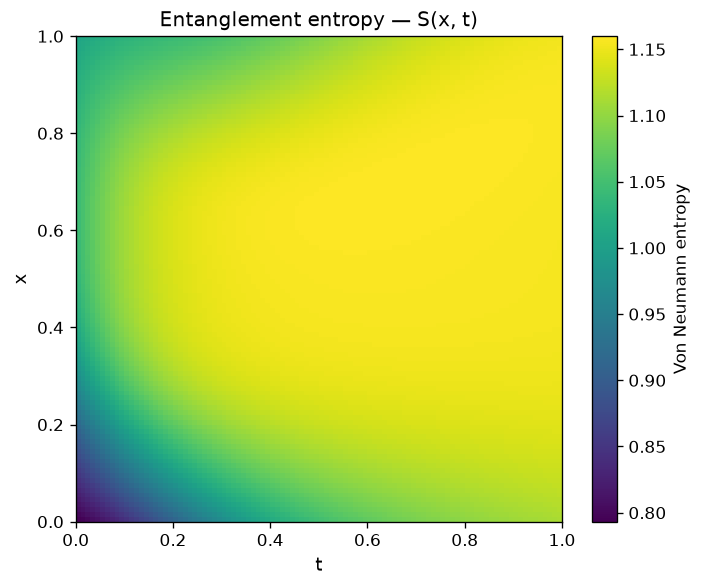

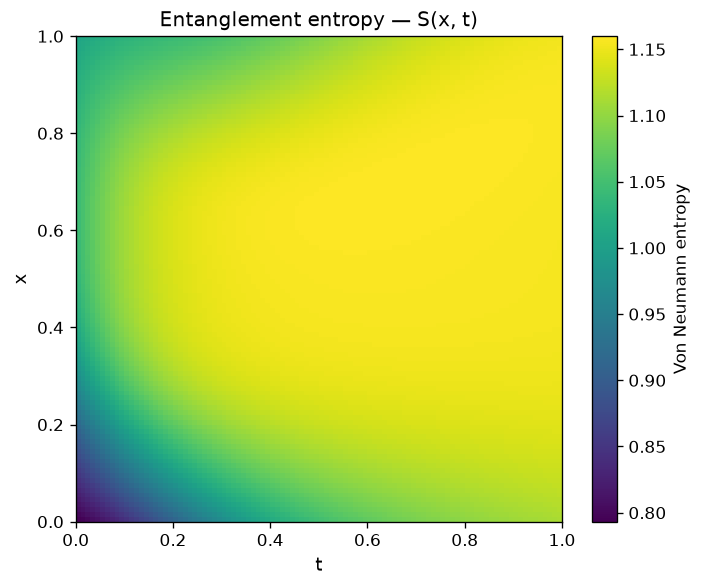

In [21]:
from src.plotter import plot_entropy_field

entropy_grids = []

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)

    train(
        model=model, pde=pde, loss_fn=total_loss,
        epochs=EPOCHS, log_every=25, seed=seed,
        device=device, dtype=dtype,
    )

    metrics_final, U_pred_final, U_true_final, x_grid_final, t_grid_final = evaluate(
        model, pde, nx=100, nt=100, device=device, dtype=dtype, verbose=True,
    )
    entropy_grids.append(metrics_final["entropy_grid"])

entropy_grids = torch.stack(entropy_grids)  # (n_seeds, nx, nt)
entropy_field_mean = entropy_grids.mean(dim=0)

plot_entropy_field(
    entropy_field_mean, x_grid_final, t_grid_final,
    save_path="figures/entanglement_entropy/entropy_field_xt.png",
    show=False,
)

## 6 - Quantum Fisher Information as a function of (x, t)

For a pure state, `F_ij = 4 * Re[<d_i psi|d_j psi> - <d_i psi|psi><psi|d_j psi>]`
(`utils.quantum_fisher_information`). `MerlinTunableSimple.amplitudes(xt)` exposes the raw
Fock-basis amplitudes as a differentiable function of xt so this can be computed via
autograd, without any new simulation infrastructure.

**Important caveat for `n_encoding_layers=1` (verified in the next cell, not just
asserted):** the angle-encoding gates are phase shifters `exp(i * phi_k * n_hat_k)`
generated by the (mutually commuting) photon-number operators, sandwiched between two
*input-independent* trainable unitaries LI, RI. For any fixed reference state
`|psi_1> = LI|input_state>`, this structure makes the QFIM in the *encoded-feature* space
phi provably constant: `F_ij(phi) = 4 * Cov_psi1(n_i, n_j)`, independent of phi and of RI
(RI acts after the phi-dependence is already fixed, and unitaries preserve inner
products, so it drops out of the QFI formula entirely). Since the only path from (x, t)
into the circuit is `phi = feature_map(x, t)`, the pullback is
`F_(x,t) = J_f^T F_phi J_f` — so for a single encoding layer, **every bump and valley in
the QFI(x, t) plot below is the classical feature map's Jacobian** (where that small Tanh
MLP is locally steep vs. flat), not the quantum encoding's own resolving power, which
doesn't vary over the domain at all. Data re-uploading (`n_encoding_layers=2`) breaks
this: a *trainable* entangling layer sits between the two encoding passes, so the
commuting-generator argument no longer applies and genuine circuit structure re-enters
the phi-dependence — also verified below.

**Cost:** unlike entropy (free, already part of the forward pass), QFI needs ~2×hilbert_dim
backward passes per evaluation (see `eval.py`'s `compute_qfi` flag) — measured at ~5s for a
100×100 grid on this M3's MPS backend, so it's enabled only for this final evaluation, not
during training.

In [ ]:
from src.utils import fisher_information

# Structural check, independent of any trained weights: sample the QFIM directly
# in the ENCODED-FEATURE space phi (bypassing feature_map / (x,t) entirely) at
# random points, for both a 1-layer and a 2-layer (re-uploading) circuit.
_check_1layer = MerlinTunableSimple(n_encoding_layers=1)
_check_2layer = MerlinTunableSimple(n_encoding_layers=2)

_phi_1layer = torch.randn(50, _check_1layer.feature_size) * 2.0
_phi_2layer = torch.randn(50, _check_1layer.feature_size * _check_2layer.n_encoding_layers) * 2.0

_qfi_1layer, _ = fisher_information(_check_1layer.quantum, _phi_1layer)
_qfi_2layer, _ = fisher_information(_check_2layer.quantum, _phi_2layer)

_trace_1layer = torch.diagonal(_qfi_1layer, dim1=-2, dim2=-1).sum(-1)
_trace_2layer = torch.diagonal(_qfi_2layer, dim1=-2, dim2=-1).sum(-1)

print(f"n_encoding_layers=1: Tr(QFI(phi)) over 50 random phi — "
      f"mean={_trace_1layer.mean():.4f}, relative std={_trace_1layer.std()/_trace_1layer.mean():.2e} "
      f"(expect ~0: provably constant)")
print(f"n_encoding_layers=2: Tr(QFI(phi)) over 50 random phi — "
      f"mean={_trace_2layer.mean():.4f}, relative std={_trace_2layer.std()/_trace_2layer.mean():.2%} "
      f"(expect clearly nonzero: re-uploading restores genuine phi-dependence)")


Seed 42
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.4899e+00 | PDE: 3.29e-08 | Cons: 2.17e-01 | IC: 5.38e-01 | BC: 8.95e-02 | Time: 0.1s
Epoch    50/300 | Loss: 4.7820e+00 | PDE: 2.45e-05 | Cons: 1.32e-04 | IC: 4.74e-01 | BC: 3.97e-02 | Time: 7.0s
Epoch   100/300 | Loss: 4.5521e+00 | PDE: 1.21e-02 | Cons: 4.38e-02 | IC: 4.49e-01 | BC: 4.74e-02 | Time: 14.1s
Epoch   150/300 | Loss: 3.9416e+00 | PDE: 5.84e-02 | Cons: 3.21e-01 | IC: 3.75e-01 | BC: 1.02e-01 | Time: 21.1s
Epoch   200/300 | Loss: 5.1166e+00 | PDE: 6.23e-02 | Cons: 2.36e-01 | IC: 4.97e-01 | BC: 6.36e-02 | Time: 28.5s
Epoch   250/300 | Loss: 3.7526e+00 | PDE: 5.86e-02 | Cons: 3.16e-01 | IC: 3.58e-01 | BC: 8.52e-02 | Time: 35.8s
Epoch   300/300 | Loss: 2.2786e+00 | PDE: 4.84e-01 | Cons: 6.43e+00 | IC: 1.12e-01 | BC: 2.94e-02 | Time: 43.2s

Done — 43.2s total
Evaluating on 100×100 grid …
  Relative L2 : 4.1418e-01
  MAE         : 5.6448e-02
  Max abs e

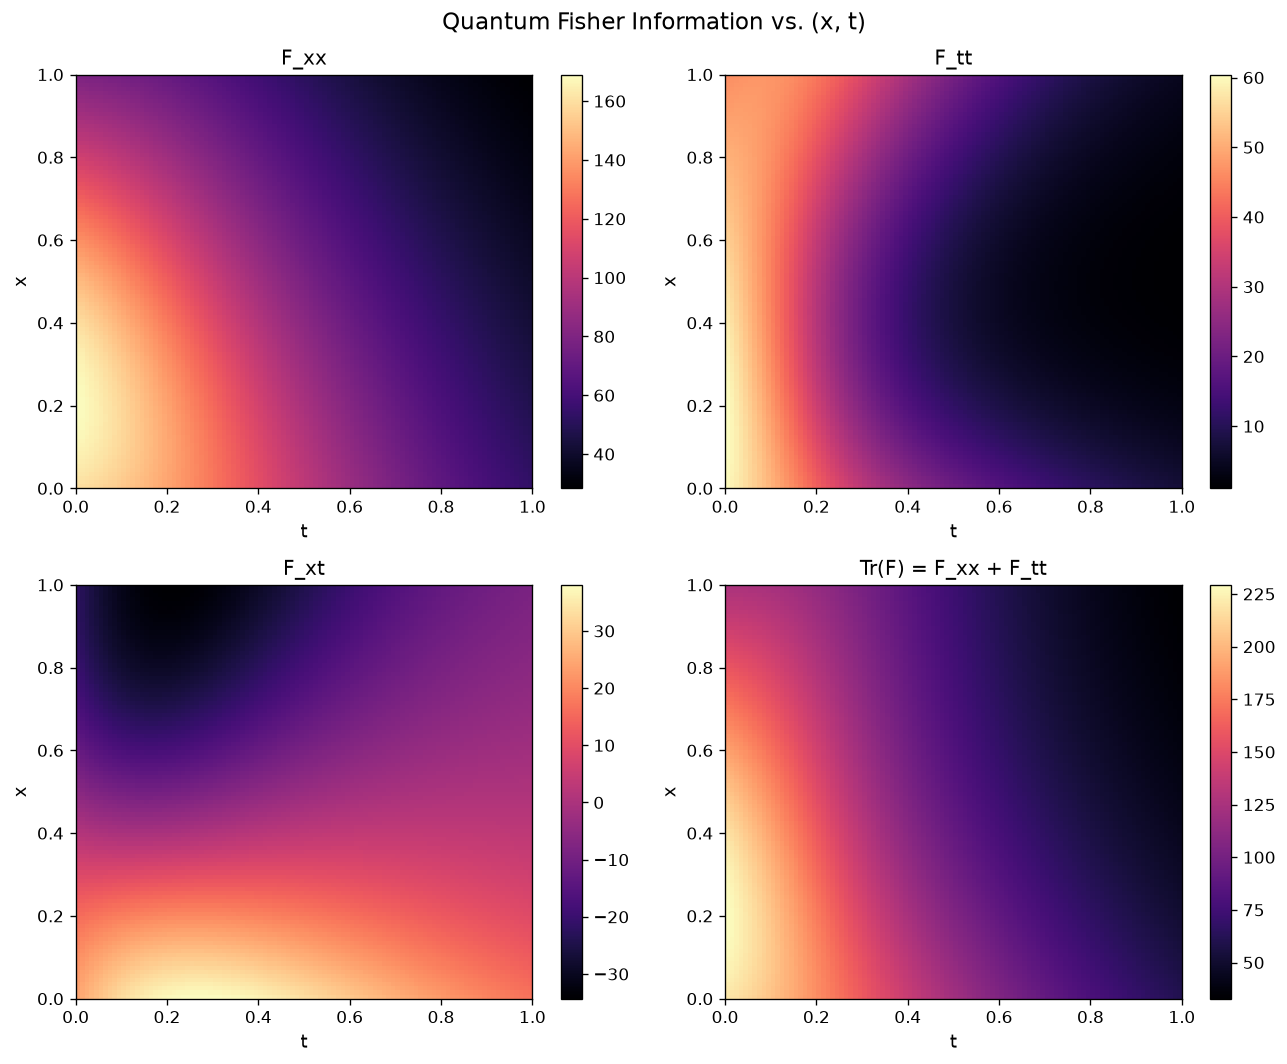

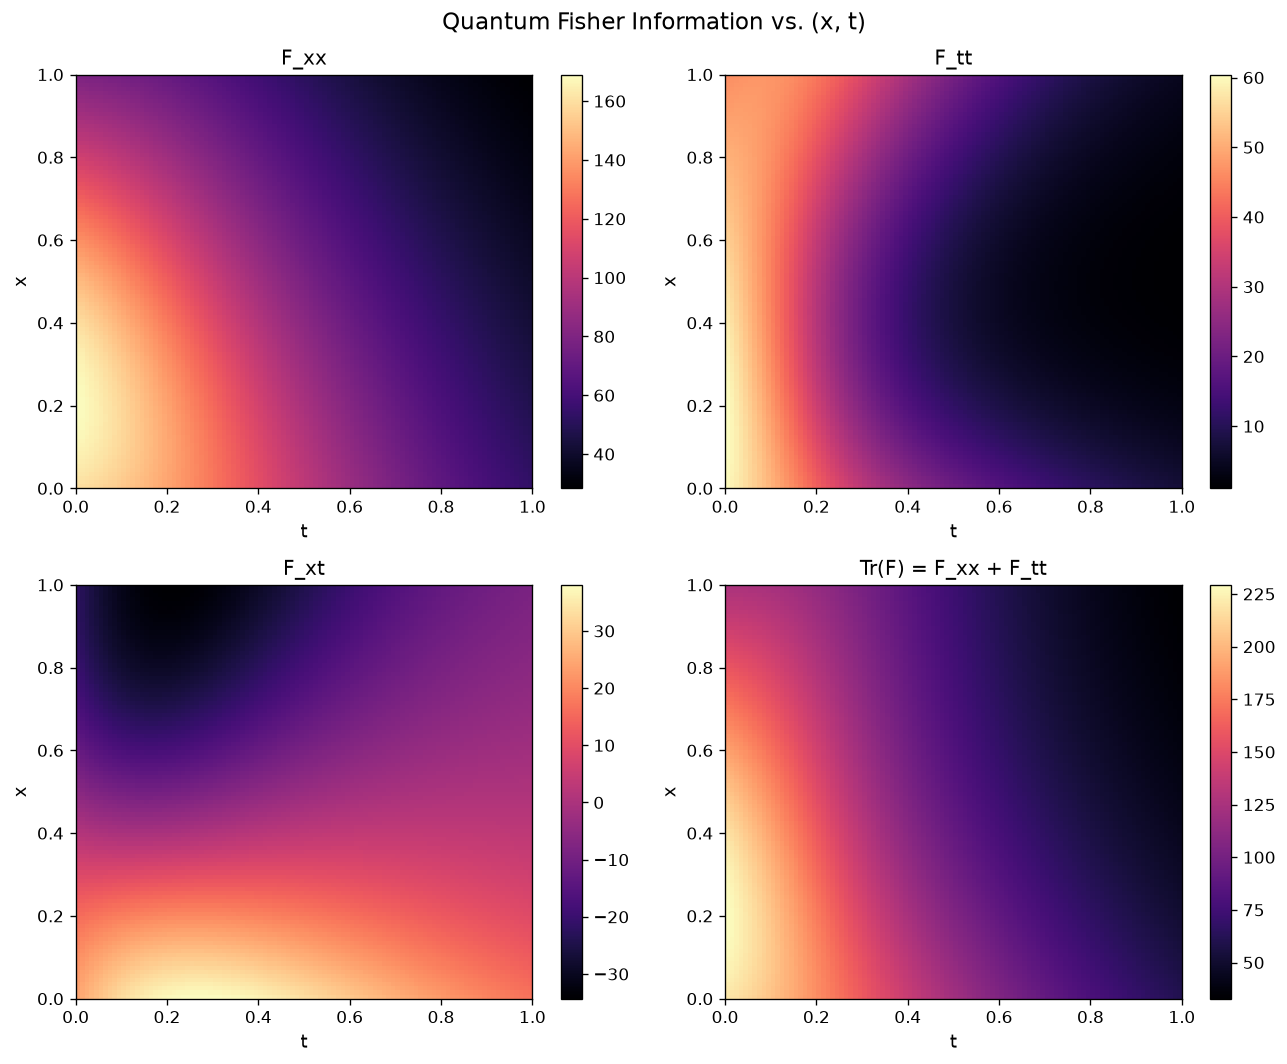

In [7]:
from src.plotter import plot_qfi_field

qfi_grids = []
cfi_grids = []

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)

    train(
        model=model, pde=pde, loss_fn=total_loss,
        epochs=EPOCHS, log_every=50, seed=seed,
        device=device, dtype=dtype,
    )

    metrics_final, U_pred_final, U_true_final, x_grid_final, t_grid_final = evaluate(
        model, pde, nx=100, nt=100, device=device, dtype=dtype, verbose=True,
        compute_qfi=True,
    )
    qfi_grids.append(metrics_final["qfi_grid"])
    cfi_grids.append(metrics_final["cfi_grid"])

qfi_grids = torch.stack(qfi_grids)  # (n_seeds, nx, nt, 2, 2)
cfi_grids = torch.stack(cfi_grids)  # (n_seeds, nx, nt, 2, 2)
qfi_field_mean = qfi_grids.mean(dim=0)
cfi_field_mean = cfi_grids.mean(dim=0)

plot_qfi_field(
    qfi_field_mean, x_grid_final, t_grid_final,
    save_path="figures/entanglement_entropy/qfi_field_xt.png",
    show=True,
)

### 6.1 - How much of that resolving power does the actual readout use?

QFI is the sensitivity of the encoded state under the *best conceivable* measurement.
This model instead reads out via Born-rule photon-counting probabilities
`q_probs = |amplitudes|^2` fed through a small classical MLP — a specific, fixed
measurement choice that generally does **not** saturate the QFI bound. The Classical
Fisher Information (CFI) of that actual probability distribution,
`F_ij = sum_k (1/p_k)(dp_k/dxt_i)(dp_k/dxt_j)`, is always <= QFI (Loewner order); the gap
is information the quantum state carries but a photon-number measurement can't see (e.g.
it's provably blind to relative phase — verified against the textbook qubit case where
CFI_tt=0 while QFI_tt=sin^2(x)>0).

**Given section 6's finding, `Tr(CFI)/Tr(QFI)` below is not quite "resolving power
actually used vs. available at (x, t)"** — for `n_encoding_layers=1`, Tr(QFI) is constant
over the domain, so the (x, t)-structure in this ratio is entirely CFI's, i.e. it reduces
to "how does the realized (not theoretical) Fisher information vary along the feature
map's trajectory `phi(x, t)`" rather than a genuine per-point encoding-vs-readout
comparison. It's still a legitimate readout-efficiency number, just not a spatial map of
where the *encoding* is more or less useful.

Saved: figures/entanglement_entropy/fisher_efficiency_xt.png


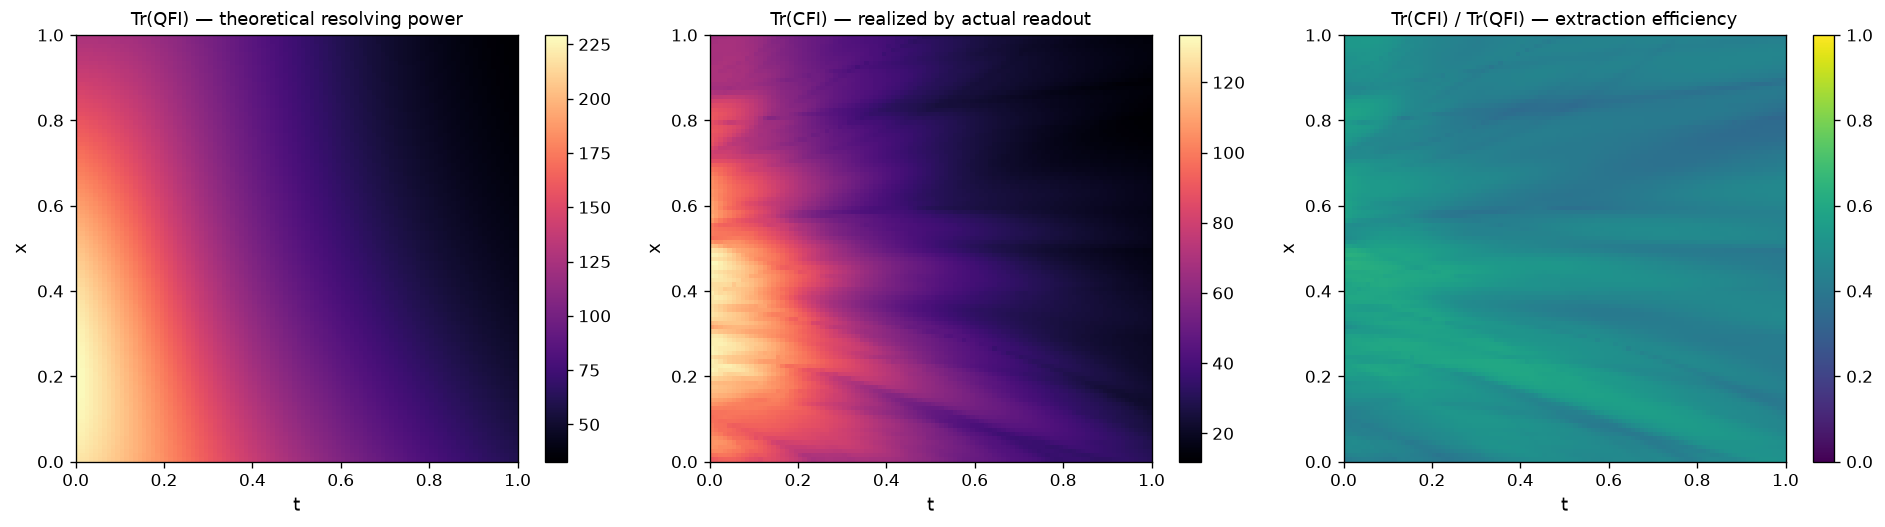

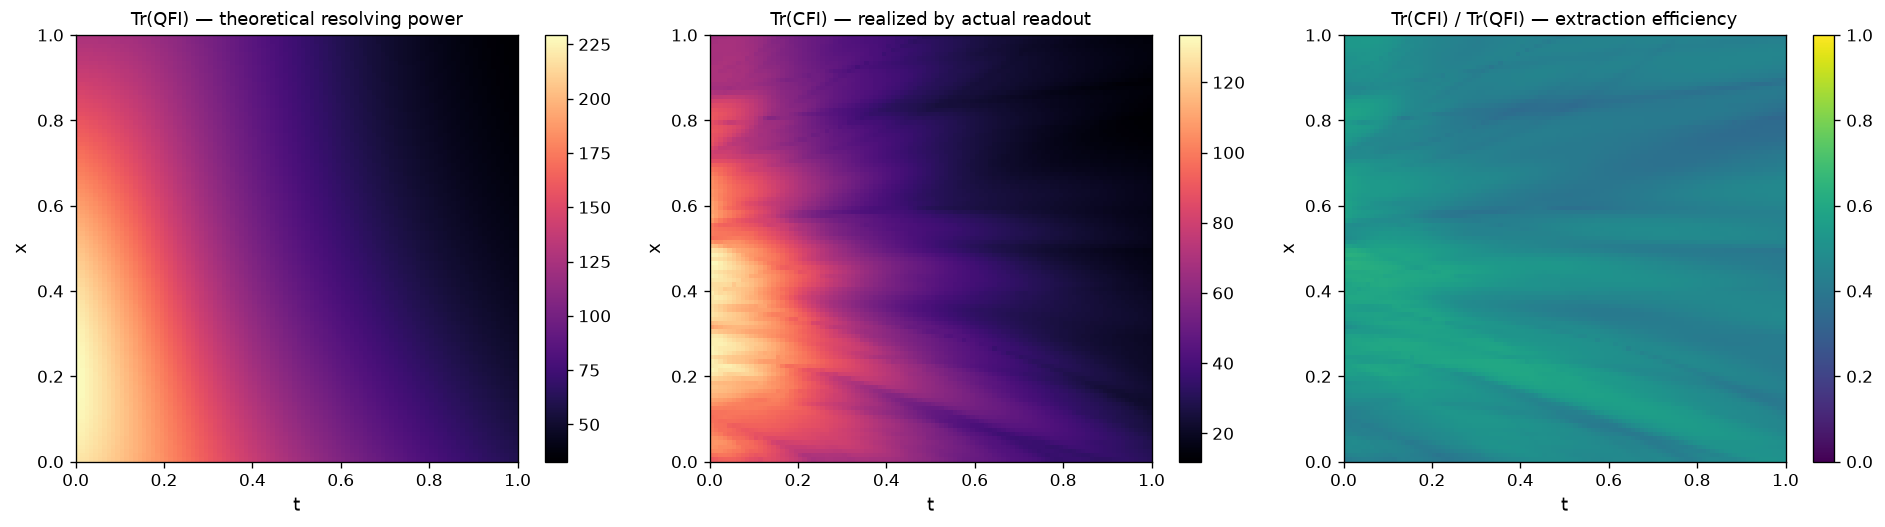

In [10]:
from src.plotter import plot_fisher_efficiency_field

plot_fisher_efficiency_field(
    qfi_field_mean, cfi_field_mean, x_grid_final, t_grid_final,
    save_path="figures/entanglement_entropy/fisher_efficiency_xt.png",
    show=True,
)

### 6.2 - Does any of this actually track prediction error?

The honest test, run directly instead of assumed: Spearman rank correlation between
`eta(x,t) = Tr(CFI)/Tr(QFI)` (and the raw traces) against the pointwise prediction error
`|u_pred - u_true|`, using the last seed's trained model and its already-computed 100x100
grid.

Two reasons to expect this to be weak or even the "wrong sign" rather than a clean
"high Fisher info -> low error" story: (1) Fisher information — quantum or classical —
characterizes the *measurement channel's* sensitivity, not whether training converged to
the right value there; those are set by target smoothness, collocation density, and
optimization, which no Fisher quantity sees. (2) In a heat equation, sensitivity tends to
concentrate where the solution itself varies fastest (steep gradients near the initial
profile) — exactly where PINNs typically accumulate the most error. So high Fisher info
coinciding with *high* error is at least as plausible as the hoped-for direction.

The trace ratio can also bury an x/t asymmetry the residual actually cares about (the PDE
residual is first-order in `d/dt` but second-order in `d/dx`), so `eta_xx` and `eta_tt`
are reported separately alongside the combined trace.

In [11]:
from scipy.stats import spearmanr

# NOTE: qfi_field_mean/cfi_field_mean are averaged over SEEDS, but
# U_pred_final/U_true_final are only the *last* seed's (evaluate() isn't
# re-run per seed for U_pred here) — comparing seed-averaged Fisher info
# against a single seed's error field is a slight mismatch; treat this as a
# first-pass check, not a rigorous multi-seed statistic.
abs_error = (U_pred_final - U_true_final).abs()

qfi_xx, qfi_tt = qfi_field_mean[..., 0, 0], qfi_field_mean[..., 1, 1]
cfi_xx, cfi_tt = cfi_field_mean[..., 0, 0], cfi_field_mean[..., 1, 1]
qfi_trace = qfi_xx + qfi_tt
cfi_trace = cfi_xx + cfi_tt
eta = cfi_trace / qfi_trace
eta_xx = cfi_xx / qfi_xx
eta_tt = cfi_tt / qfi_tt

def _rho(name, field):
    r, p = spearmanr(field.flatten().numpy(), abs_error.flatten().numpy())
    print(f"  rho({name:22s}, |error|) = {r:+.4f}   (p={p:.1e})")

print("Spearman rank correlation with pointwise prediction error:")
_rho("Tr(QFI)", qfi_trace)
_rho("Tr(CFI)", cfi_trace)
_rho("eta = Tr(CFI)/Tr(QFI)", eta)
_rho("eta_xx = CFI_xx/QFI_xx", eta_xx)
_rho("eta_tt = CFI_tt/QFI_tt", eta_tt)

Spearman rank correlation with pointwise prediction error:
  rho(Tr(QFI)               , |error|) = +0.0540   (p=6.4e-08)
  rho(Tr(CFI)               , |error|) = +0.0310   (p=1.9e-03)
  rho(eta = Tr(CFI)/Tr(QFI) , |error|) = -0.0454   (p=5.5e-06)
  rho(eta_xx = CFI_xx/QFI_xx, |error|) = +0.0522   (p=1.7e-07)
  rho(eta_tt = CFI_tt/QFI_tt, |error|) = -0.2465   (p=2.5e-138)


Saved: ../figures/demo/solution_quant.png


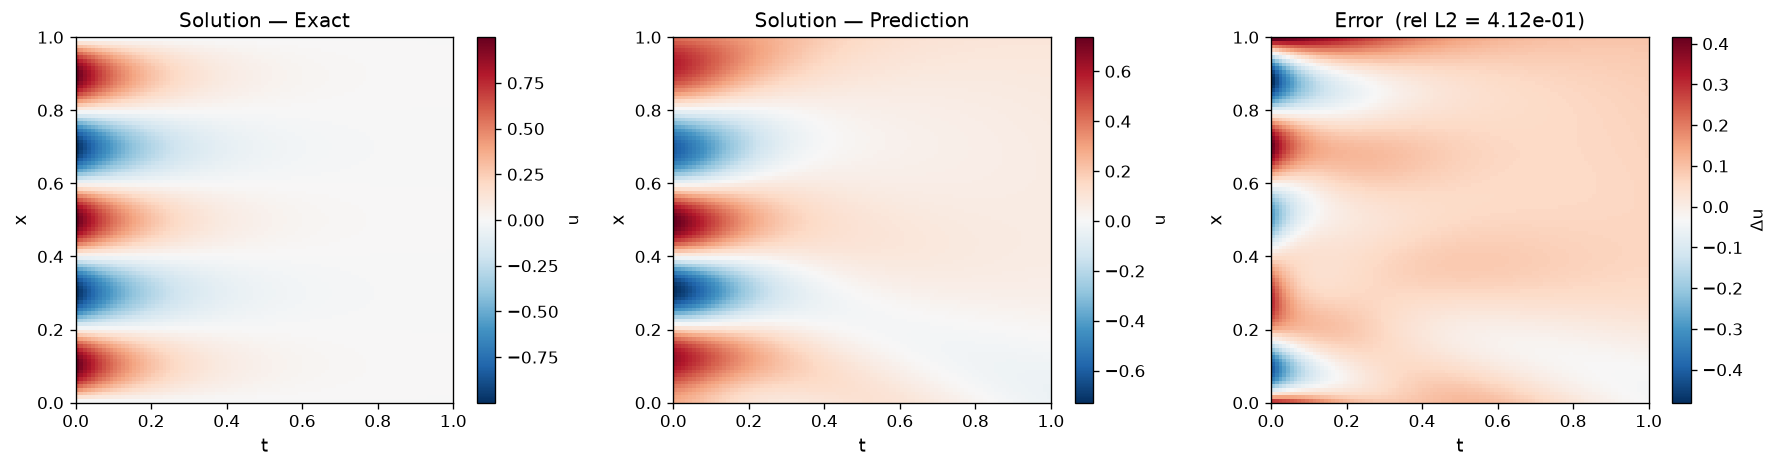

Relative L2 error: 4.1237e-01


In [12]:
fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred_final,
    U_true    = U_true_final,
    x_grid    = x_grid_final,
    t_grid    = t_grid_final,
    save_path ='../figures/demo/solution_quant.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')

## 7 - Empirical NTK / spectral alignment

Section 6 showed entanglement entropy and Fisher information don't track prediction
error — they characterize the encoding's intrinsic structure and its measurement
channel, not whether training converged to the right value anywhere. This section asks
a different question: does the model's *representational capacity*, viewed through its
Neural Tangent Kernel, align with the target function's structure?

For a model `f(x; theta)`, the empirical NTK Gram matrix on a fixed point set is
`K = J J^T` where `J[i,:] = d f(x_i)/d theta` (`ntk.output_jacobian`). Under linearized
("lazy") training theory (Jacot et al. 2018), the model's *learning dynamics* — which
target components converge fast vs. slow — are governed by this kernel's eigenspectrum
at initialization: projecting the target onto the top eigendirections predicts how much
of it the model can represent early/easily (Canatar, Bordelon & Pehlevan 2021,
"Spectral bias and task-model alignment..."), and for PINNs specifically, error
concentrates in low-NTK-eigenvalue directions of the residual (Wang, Yu & Perdikaris
2022, "When and why PINNs fail to train: A neural tangent kernel perspective").

`src/ntk.py` implements this: `empirical_ntk` (Gram + eigendecomposition),
`spectral_power_curve` (cumulative target power `C(k)` in the top-k eigendirections),
and `project_low_eigenvalue_subspace` (reconstructing a field, e.g. the error, from only
the slow-learning directions). All three are validated against an analytic case — for a
linear model `f(x)=theta^T phi(x)`, the NTK must equal `phi(x)^T phi(x')` exactly, which
also gives an exact low-rank cutoff to check eigenvalue truncation, orthonormality, and
reconstruction against.

**Methodological note:** NTK-at-initialization means the actual pre-training parameters
of a *specific* model instance, not a separately re-initialized one — `train()` seeds
internally but the model is constructed (and thus initialized) *before* `train()` is
called, so a freshly re-instantiated "comparison" model would not reproduce the same
initial weights. Section 7.3 below snapshots `state_dict()` immediately after
construction, before training, to keep this correct.

**Cost:** unlike the batched grad-of-sum tricks behind entropy/QFI/CFI, NTK needs one
backward pass *per grid point* (can't be summed away), so it doesn't benefit from the
same trick — measured at ~12s for a 30x30 grid on the quantum model (P=310 params) and
~1.4s on the parameter-matched classical model on this M3's MPS backend.

### 7.1 - Quantum vs. parameter-matched classical: target power capture C(k)

For each seed, builds a fresh quantum model and its `match_classical_param_count`
classical counterpart (same construction as section 4), computes both models' NTK at
initialization on a 30x30 grid, and projects the exact PDE solution onto each spectrum.
Higher `C(k)` at small `k` means more of the (possibly high-frequency, since
`pde.freq` may be large) target's power sits in that model's fast-learning directions.


Seed 42

Seed 666

Seed 69

Seed 67

Seed 13
Saved: figures/entanglement_entropy/ntk_spectrum.png


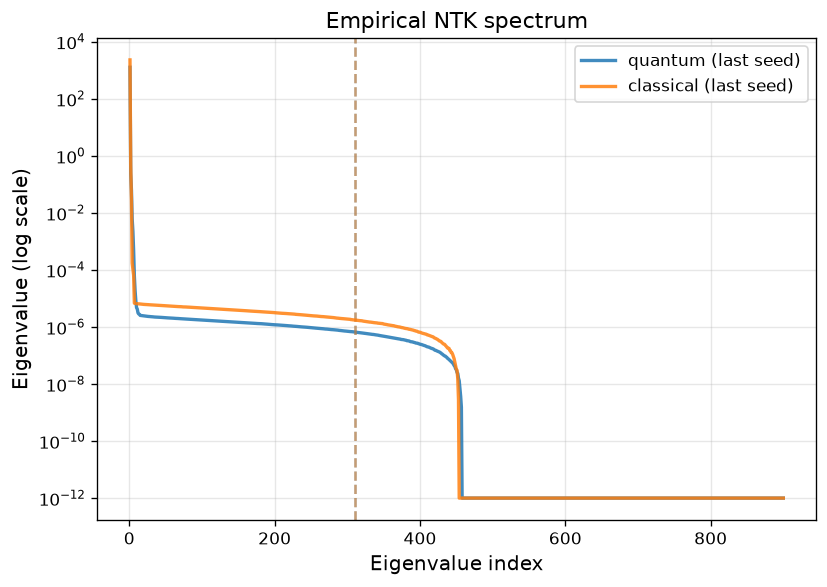

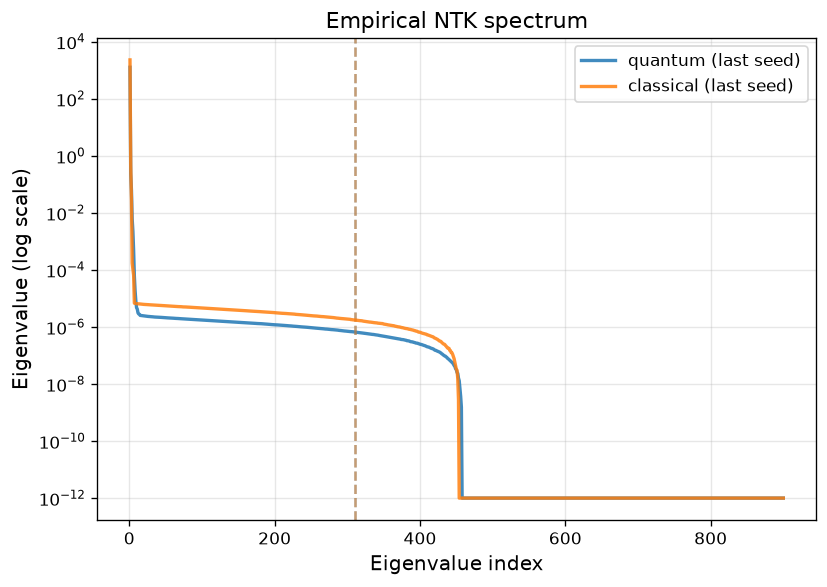

In [13]:
from src.models import match_classical_param_count
from src.ntk import empirical_ntk, spectral_power_curve
from src.plotter import plot_ntk_spectrum, plot_spectral_alignment

NTK_NX, NTK_NT = 30, 30
x_spec = torch.linspace(pde.x_min, pde.x_max, NTK_NX, device=device, dtype=dtype).reshape(-1, 1)
t_spec = torch.linspace(pde.t_min, pde.t_max, NTK_NT, device=device, dtype=dtype).reshape(-1, 1)
X_spec, T_spec = torch.meshgrid(x_spec.squeeze(), t_spec.squeeze(), indexing="ij")
xt_spec = torch.stack([X_spec.reshape(-1), T_spec.reshape(-1)], dim=1)
u_true_spec = pde.exact_solution(xt_spec[:, 0:1], xt_spec[:, 1:2]).reshape(-1).cpu()

eigvals_q_last = eigvals_c_last = None
C_q_runs, C_c_runs = [], []

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    torch.manual_seed(seed)
    quantum_init = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)
    classical_init = match_classical_param_count(
        quantum_init, feature_size=4, n_encoding_layers=n_encoding_layers
    ).to(device)

    eigvals_q, eigvecs_q = empirical_ntk(quantum_init, xt_spec)
    eigvals_c, eigvecs_c = empirical_ntk(classical_init, xt_spec)
    eigvals_q_last, eigvals_c_last = eigvals_q, eigvals_c  # keep the last seed's spectra to plot

    C_q_runs.append(spectral_power_curve(eigvecs_q, eigvals_q, u_true_spec))
    C_c_runs.append(spectral_power_curve(eigvecs_c, eigvals_c, u_true_spec))

q_params = sum(p.numel() for p in quantum_init.parameters())
c_params = sum(p.numel() for p in classical_init.parameters())

plot_ntk_spectrum(
    {"quantum (last seed)": eigvals_q_last, "classical (last seed)": eigvals_c_last},
    param_counts={"quantum (last seed)": q_params, "classical (last seed)": c_params},
    save_path="figures/entanglement_entropy/ntk_spectrum.png",
    show=True,
)

### 7.2 - Aggregate C(k) across seeds

Saved: figures/entanglement_entropy/spectral_alignment.png


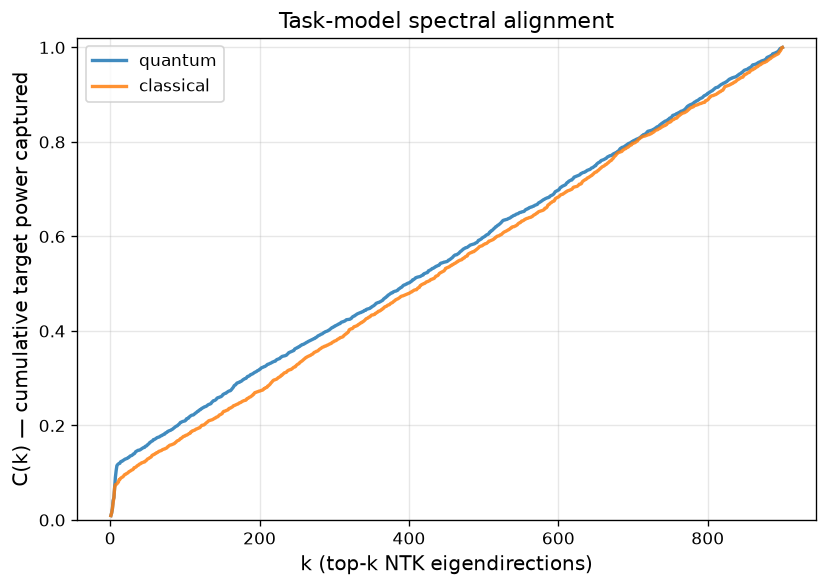

Averaged over 5 seeds (mean ± std):
  C( 10): quantum=0.1172±0.0044   classical=0.0786±0.0112
  C( 20): quantum=0.1288±0.0073   classical=0.0965±0.0234
  C( 35): quantum=0.1454±0.0115   classical=0.1128±0.0217


In [14]:
C_q_mean = torch.stack(C_q_runs).mean(dim=0)
C_c_mean = torch.stack(C_c_runs).mean(dim=0)

plot_spectral_alignment(
    {"quantum": C_q_mean, "classical": C_c_mean},
    save_path="figures/entanglement_entropy/spectral_alignment.png",
    show=True,
)

print(f"Averaged over {len(SEEDS)} seeds (mean ± std):")
for k in [10, 20, 35]:
    q_vals = torch.stack([C[k - 1] for C in C_q_runs])
    c_vals = torch.stack([C[k - 1] for C in C_c_runs])
    print(f"  C({k:3d}): quantum={q_vals.mean():.4f}±{q_vals.std():.4f}   "
          f"classical={c_vals.mean():.4f}±{c_vals.std():.4f}")

### 7.3 - Does persistent error localize to the low-eigenvalue NTK subspace?

Trains one quantum model (single seed, for cost), having snapshotted its `state_dict()`
immediately after construction so the NTK below is genuinely "at this model's actual
initialization" rather than a mismatched fresh instance. Projects the trained model's
pointwise error field onto the bottom half of that init-NTK's eigendirections
(`project_low_eigenvalue_subspace`, `frac=0.5`) and compares it to the actual error.

Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.0028e+00 | PDE: 6.38e-06 | Cons: 1.64e-02 | IC: 5.00e-01 | BC: 4.89e-03 | Time: 0.1s
Epoch   300/300 | Loss: 1.6037e+00 | PDE: 2.75e-01 | Cons: 5.53e+00 | IC: 7.41e-02 | BC: 3.44e-02 | Time: 42.9s

Done — 42.9s total
Saved: figures/entanglement_entropy/low_eigenvalue_error_field.png


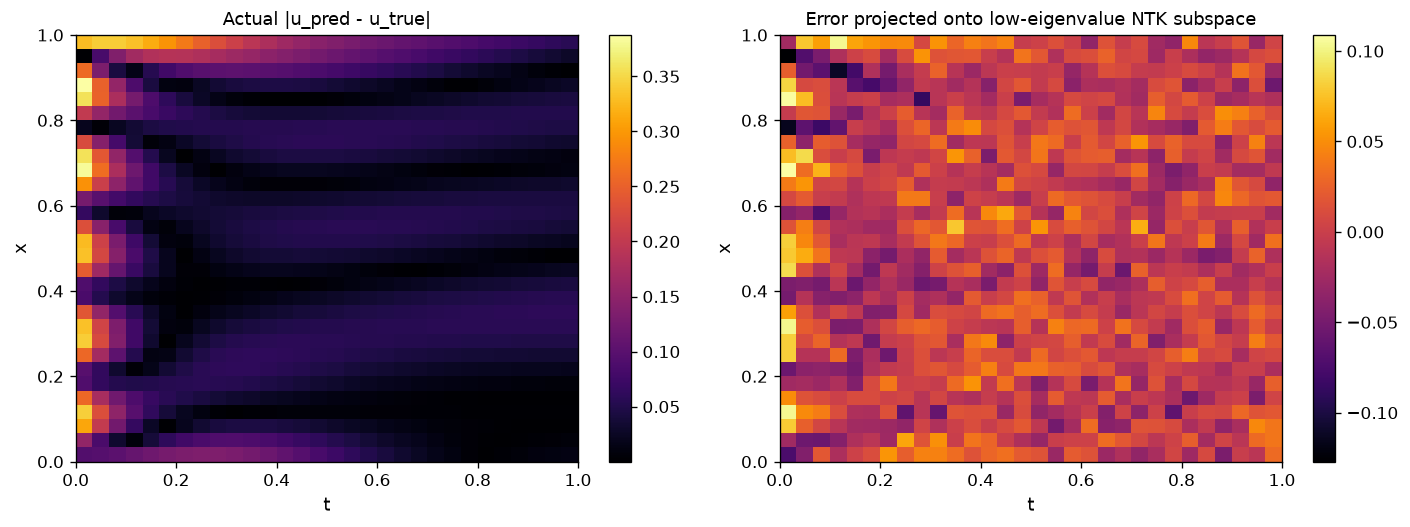

Spearman rho(low-eigenvalue-projected error, actual |error|) = +0.3367  (p=2.7e-25)


In [15]:
import copy
from src.ntk import project_low_eigenvalue_subspace
from src.plotter import plot_low_eigenvalue_error_field

torch.manual_seed(SEEDS[0])
ntk_model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)
init_state = copy.deepcopy(ntk_model.state_dict())  # snapshot BEFORE training

train(
    model=ntk_model, pde=pde, loss_fn=total_loss,
    epochs=EPOCHS, log_every=EPOCHS, seed=SEEDS[0],
    device=device, dtype=dtype,
)

ntk_model.eval()
with torch.no_grad():
    u_pred_ntk = ntk_model(xt_spec)[0].reshape(NTK_NX, NTK_NT).cpu()
u_true_ntk = pde.exact_solution(xt_spec[:, 0:1], xt_spec[:, 1:2]).reshape(NTK_NX, NTK_NT).cpu()
error_field = (u_pred_ntk - u_true_ntk).abs()

init_model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)
init_model.load_state_dict(init_state)
eigvals_init, eigvecs_init = empirical_ntk(init_model, xt_spec)

error_low = project_low_eigenvalue_subspace(
    eigvecs_init, eigvals_init, error_field.flatten(), frac=0.5
).reshape(NTK_NX, NTK_NT)

plot_low_eigenvalue_error_field(
    error_field, error_low, x_spec.cpu(), t_spec.cpu(),
    save_path="figures/entanglement_entropy/low_eigenvalue_error_field.png",
    show=True,
)

from scipy.stats import spearmanr
rho, p = spearmanr(error_low.flatten().numpy(), error_field.flatten().numpy())
print(f"Spearman rho(low-eigenvalue-projected error, actual |error|) = {rho:+.4f}  (p={p:.1e})")